# Two-Way ANOVA (Without Replication) — A Practical Walkthrough

**Problem:** A company wants to test whether **three salespersons** perform differently
across **four regions**. Only **one sales value** (₹ thousand) is recorded per
salesperson-region combination — so there is **no replication** (no repeated observations
within a cell), and therefore **no interaction effect can be tested**.

| | Region 1 | Region 2 | Region 3 | Region 4 |
|---|---|---|---|---|
| **Salesperson 1** | 10 | 14 | 12 | 16 |
| **Salesperson 2** | 8 | 10 | 9 | 12 |
| **Salesperson 3** | 15 | 18 | 16 | 20 |

---
### Why Two-Way ANOVA?

We have **two categorical factors** affecting one numeric outcome (sales):
1. **Rows factor** → Salesperson (3 levels)
2. **Columns factor** → Region (4 levels)

Two-Way ANOVA (without replication) lets us test **both factors at once**, rather than
running two separate one-way ANOVAs.

### The Hypotheses

**For Rows (Salespersons):**
- H₀: All salespersons have equal mean sales (μ₁ = μ₂ = μ₃)
- H₁: At least one salesperson's mean sales differs

**For Columns (Regions):**
- H₀: All regions have equal mean sales (μ₁ = μ₂ = μ₃ = μ₄)
- H₁: At least one region's mean sales differs

We test both at **α = 0.05**.


## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

sns.set_style("whitegrid")
%matplotlib inline


## Step 2: Enter the Data

This is a small, fixed dataset (given directly in the problem), so we build it manually
as a pandas DataFrame in **long format** — one row per observation, with columns for
`salesperson`, `region`, and `sales`. This is the format `statsmodels` expects.


In [2]:
data = {
    'salesperson': ['S1','S1','S1','S1',
                     'S2','S2','S2','S2',
                     'S3','S3','S3','S3'],
    'region':      ['R1','R2','R3','R4',
                     'R1','R2','R3','R4',
                     'R1','R2','R3','R4'],
    'sales':       [10, 14, 12, 16,
                     8, 10, 9, 12,
                     15, 18, 16, 20]
}

df = pd.DataFrame(data)
df


,salesperson,region,sales
0,S1,R1,10
1,S1,R2,14
2,S1,R3,12
3,S1,R4,16
4,S2,R1,8
5,S2,R2,10
6,S2,R3,9
7,S2,R4,12
8,S3,R1,15
9,S3,R2,18


In [3]:
# Same data in the original "wide" table format, for a visual check
pivot = df.pivot(index='salesperson', columns='region', values='sales')
pivot['Row Total'] = pivot.sum(axis=1)
pivot['Row Mean'] = pivot[['R1','R2','R3','R4']].mean(axis=1)
pivot.loc['Column Total'] = pivot.sum()
pivot.loc['Column Mean'] = pivot.loc[[ 'S1','S2','S3']].mean()
pivot


/tmp/ipykernel_213972/294670526.py:6: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  pivot.loc['Column Mean'] = pivot.loc[[ 'S1','S2','S3']].mean()
/tmp/ipykernel_213972/294670526.py:6: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  pivot.loc['Column Mean'] = pivot.loc[[ 'S1','S2','S3']].mean()


region,R1,R2,R3,R4,Row Total,Row Mean
salesperson,,,,,,
S1,10,14,12.000000,16,52.000000,13.000000
S2,8,10,9.000000,12,39.000000,9.750000
S3,15,18,16.000000,20,69.000000,17.250000
Column Total,33,42,37.000000,48,160.000000,40.000000
Column Mean,11,14,12.333333,16,53.333333,13.333333


## Step 3: Visualize the Data

An **interaction plot** is the standard way to look at two-factor data — one line per
salesperson, showing how their sales change across regions.


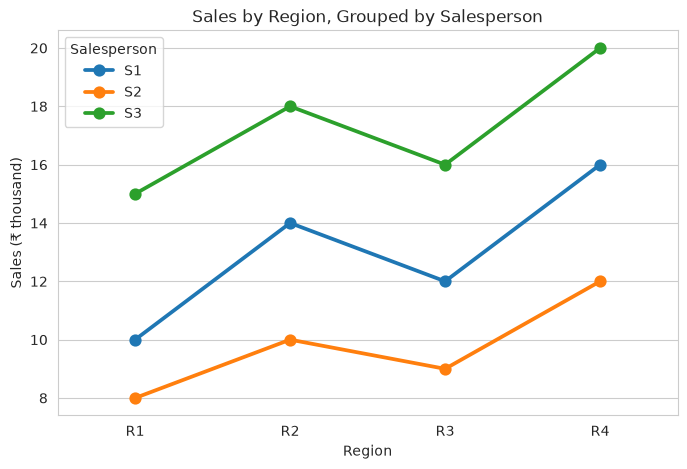

In [4]:
plt.figure(figsize=(8,5))
sns.pointplot(data=df, x='region', y='sales', hue='salesperson',
              order=['R1','R2','R3','R4'], markers='o')
plt.title('Sales by Region, Grouped by Salesperson')
plt.ylabel('Sales (₹ thousand)')
plt.xlabel('Region')
plt.legend(title='Salesperson')
plt.show()


Notice the lines are roughly **parallel** — each salesperson's sales rise and fall
across regions in a similar pattern. This is a visual sign that there's **no strong
interaction** between salesperson and region (which fits — we only have 1 value per
cell, so we can't formally test interaction anyway).


## Step 4: Grand Mean and Group Means


In [5]:
grand_mean = df['sales'].mean()
N = len(df)

row_means = df.groupby('salesperson')['sales'].mean()
col_means = df.groupby('region')['sales'].mean()

print(f"Grand Total = {df['sales'].sum()}")
print(f"N = {N}")
print(f"Grand Mean = {grand_mean:.3f}")
print()
print("Row Means (Salespersons):")
print(row_means)
print()
print("Column Means (Regions):")
print(col_means)


Grand Total = 160
N = 12
Grand Mean = 13.333

Row Means (Salespersons):
salesperson
S1    13.00
S2     9.75
S3    17.25
Name: sales, dtype: float64

Column Means (Regions):
region
R1    11.000000
R2    14.000000
R3    12.333333
R4    16.000000
Name: sales, dtype: float64


## Step 5: Manual Calculation — Sum of Squares

This section reproduces the **by-hand calculation** step by step, so you can see exactly
where each number in the ANOVA table comes from.

**Total Sum of Squares (SST):**  
$$SST = \sum\sum (X_{ij} - \bar{X})^2$$

**Sum of Squares for Rows / Salespersons (SSR):**  
$$SSR = c \times \sum (\bar{X}_{i.} - \bar{X})^2$$

**Sum of Squares for Columns / Regions (SSC):**  
$$SSC = r \times \sum (\bar{X}_{.j} - \bar{X})^2$$

**Sum of Squares for Error (SSE):**  
$$SSE = SST - SSR - SSC$$


In [6]:
r = df['salesperson'].nunique()   # number of rows (salespersons) = 3
c = df['region'].nunique()        # number of columns (regions) = 4

# SST
SST = ((df['sales'] - grand_mean)**2).sum()

# SSR (rows = salespersons)
SSR = c * ((row_means - grand_mean)**2).sum()

# SSC (columns = regions)
SSC = r * ((col_means - grand_mean)**2).sum()

# SSE (by subtraction)
SSE = SST - SSR - SSC

print(f"SST = {SST:.3f}")
print(f"SSR (Salespersons) = {SSR:.3f}")
print(f"SSC (Regions)      = {SSC:.3f}")
print(f"SSE (Error)        = {SSE:.3f}")


SST = 156.667
SSR (Salespersons) = 113.167
SSC (Regions)      = 42.000
SSE (Error)        = 1.500


## Step 6: Degrees of Freedom, Mean Squares, and F-Ratios


In [7]:
df_rows  = r - 1
df_cols  = c - 1
df_error = (r-1)*(c-1)
df_total = N - 1

MSR = SSR / df_rows
MSC = SSC / df_cols
MSE = SSE / df_error

F_rows = MSR / MSE
F_cols = MSC / MSE

print(f"df (rows/salespersons) = {df_rows}")
print(f"df (columns/regions)   = {df_cols}")
print(f"df (error)             = {df_error}")
print(f"df (total)             = {df_total}")
print()
print(f"MSR = {MSR:.3f}")
print(f"MSC = {MSC:.3f}")
print(f"MSE = {MSE:.3f}")
print()
print(f"F (rows/salespersons) = {F_rows:.2f}")
print(f"F (columns/regions)   = {F_cols:.2f}")


df (rows/salespersons) = 2
df (columns/regions)   = 3
df (error)             = 6
df (total)             = 11

MSR = 56.583
MSC = 14.000
MSE = 0.250

F (rows/salespersons) = 226.33
F (columns/regions)   = 56.00


## Step 6b: Build the Summary ANOVA Table


In [8]:
anova_summary = pd.DataFrame({
    'Source': ['Rows (Salespersons)', 'Columns (Regions)', 'Error', 'Total'],
    'SS':     [round(SSR,3), round(SSC,3), round(SSE,3), round(SST,3)],
    'df':     [df_rows, df_cols, df_error, df_total],
    'MS':     [round(MSR,3), round(MSC,3), round(MSE,3), None],
    'F':      [round(F_rows,2), round(F_cols,2), None, None]
})
anova_summary


,Source,SS,df,MS,F
0,Rows (Salespersons),113.167,2,56.583,226.33
1,Columns (Regions),42.000,3,14.000,56.00
2,Error,1.500,6,0.250,NaN
3,Total,156.667,11,NaN,NaN


## Step 7: P-values and Critical F Values

Instead of looking up F-critical values in a table, we calculate the exact p-value from
the F-distribution, and also compute the critical F value for reference (both give the
same decision).


In [9]:
alpha = 0.05

# p-values from the F-distribution
p_rows = 1 - stats.f.cdf(F_rows, df_rows, df_error)
p_cols = 1 - stats.f.cdf(F_cols, df_cols, df_error)

# Critical F values (for comparison with the by-hand table lookup)
F_crit_rows = stats.f.ppf(1 - alpha, df_rows, df_error)
F_crit_cols = stats.f.ppf(1 - alpha, df_cols, df_error)

print("Rows (Salespersons):")
print(f"  F = {F_rows:.2f}, F-critical = {F_crit_rows:.2f}, p-value = {p_rows:.6f}")
print()
print("Columns (Regions):")
print(f"  F = {F_cols:.2f}, F-critical = {F_crit_cols:.2f}, p-value = {p_cols:.6f}")


Rows (Salespersons):
  F = 226.33, F-critical = 5.14, p-value = 0.000002

Columns (Regions):
  F = 56.00, F-critical = 4.76, p-value = 0.000089


## Step 8: Decision


In [10]:
print("--- Salespersons (Rows) ---")
if F_rows > F_crit_rows:
    print(f"F ({F_rows:.2f}) > F-critical ({F_crit_rows:.2f}) => Reject H0")
    print("=> Salespersons differ significantly in mean sales.")
else:
    print(f"F ({F_rows:.2f}) <= F-critical ({F_crit_rows:.2f}) => Fail to reject H0")

print()
print("--- Regions (Columns) ---")
if F_cols > F_crit_cols:
    print(f"F ({F_cols:.2f}) > F-critical ({F_crit_cols:.2f}) => Reject H0")
    print("=> Regions differ significantly in mean sales.")
else:
    print(f"F ({F_cols:.2f}) <= F-critical ({F_crit_cols:.2f}) => Fail to reject H0")


--- Salespersons (Rows) ---
F (226.33) > F-critical (5.14) => Reject H0
=> Salespersons differ significantly in mean sales.

--- Regions (Columns) ---
F (56.00) > F-critical (4.76) => Reject H0
=> Regions differ significantly in mean sales.


## Step 9: Verify with `statsmodels` (Built-in Two-Way ANOVA)

Now let's confirm the manual calculation using `statsmodels`, which is what you'd use in
practice for any dataset (not just this small example). Since there's no replication,
we fit an **additive model** (no interaction term: `salesperson + region`, not
`salesperson * region`).


In [11]:
model = ols('sales ~ C(salesperson) + C(region)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
anova_table


,sum_sq,df,F,PR(>F)
C(salesperson),113.166667,2.0,226.333333,0.000002
C(region),42.000000,3.0,56.000000,0.000089
Residual,1.500000,6.0,NaN,NaN


Compare this table to the manual one in Step 6b — the **Sum of Squares, df, F, and
p-values should match** (statsmodels reports p-values as `PR(>F)`).


## Summary

| Step | What we did |
|---|---|
| 1 | Entered the salesperson x region sales data (no replication — 1 value per cell) |
| 2 | Visualized it with an interaction plot to check for parallel trends |
| 3 | Manually calculated SST, SSR, SSC, SSE from first principles |
| 4 | Built the degrees of freedom, Mean Squares, and F-ratios |
| 5 | Computed exact p-values and critical F-values from the F-distribution |
| 6 | Verified everything against `statsmodels`' built-in two-way ANOVA |

**Conclusion:** Both **salesperson** (F = 226.33, p < 0.05) and **region** (F = 56.00,
p < 0.05) have a statistically significant effect on sales. In other words, **who** is
selling and **where** they are selling both matter.

**Note on interaction:** Because there's only **one observation per salesperson-region
combination** (no replication), we cannot test whether the effect of region *depends on*
which salesperson it is (interaction effect) — that would require repeated measurements
per cell (e.g., multiple months of sales per salesperson-region pair).
